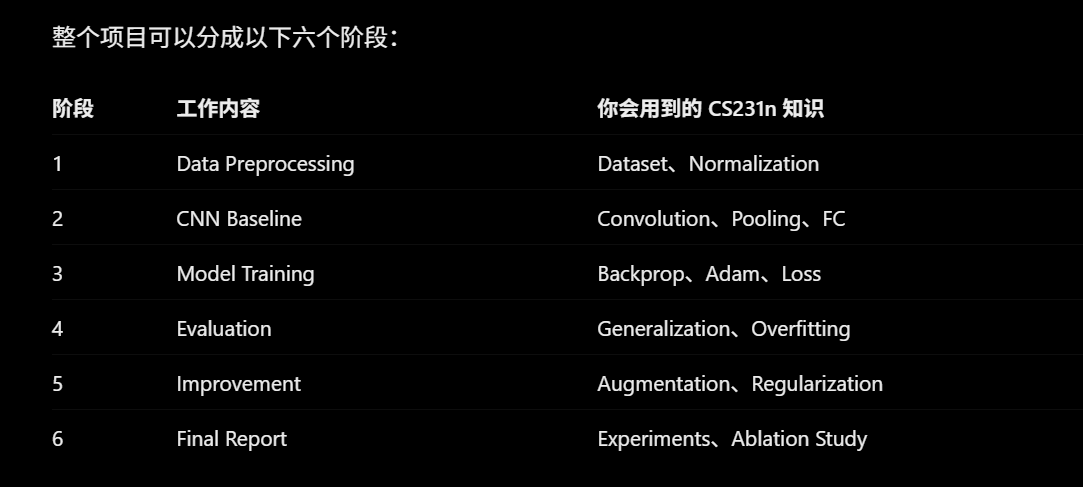

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

**Read the data**

In [2]:
train = pd.read_json("data/train.json")

print(train.shape)
train.head()

(1604, 5)


,id,band_1,band_2,inc_angle,is_iceberg
0,dfd5f913,"[-27.878360999999998, -27.15416, -28.668615, -...","[-27.154118, -29.537888, -31.0306, -32.190483,...",43.9239,0
1,e25388fd,"[-12.242375, -14.920304999999999, -14.920363, ...","[-31.506321, -27.984554, -26.645678, -23.76760...",38.1562,0
2,58b2aaa0,"[-24.603676, -24.603714, -24.871029, -23.15277...","[-24.870956, -24.092632, -20.653963, -19.41104...",45.2859,1
3,4cfc3a18,"[-22.454607, -23.082819, -23.998013, -23.99805...","[-27.889421, -27.519794, -27.165262, -29.10350...",43.8306,0
4,271f93f4,"[-26.006956, -23.164886, -23.164886, -26.89116...","[-27.206915, -30.259186, -30.259186, -23.16495...",35.6256,0


In [3]:
test = pd.read_json("data/test.json")

print(test.shape)
test.head()

(8424, 4)


,id,band_1,band_2,inc_angle
0,5941774d,"[-15.863251, -15.201077, -17.887735, -19.17248...","[-21.629612, -21.142353, -23.908337, -28.34524...",34.966400
1,4023181e,"[-26.058969497680664, -26.058969497680664, -26...","[-25.754207611083984, -25.754207611083984, -25...",32.615072
2,b20200e4,"[-14.14109992980957, -15.064241409301758, -17....","[-14.74563980102539, -14.590410232543945, -14....",37.505433
3,e7f018bb,"[-12.167478, -13.706167, -16.54837, -13.572674...","[-24.32222, -26.375538, -24.096739, -23.8769, ...",34.473900
4,4371c8c3,"[-23.37459373474121, -26.02718162536621, -28.1...","[-25.72234344482422, -27.011577606201172, -23....",43.918874


**Split labeled data into 80% training and 20% validation sets**

In [4]:
train_df, val_df = train_test_split(
    train,
    test_size=0.2,
    random_state=42,
    stratify=train["is_iceberg"]#stratify data according to fraction of IB and ship
    
)

In [5]:
train["is_iceberg"].value_counts()

is_iceberg
0    851
1    753
Name: count, dtype: int64

**No significant class imbalance.**

In [6]:
train.isnull().sum()

id            0
band_1        0
band_2        0
inc_angle     0
is_iceberg    0
dtype: int64

**No missing value**

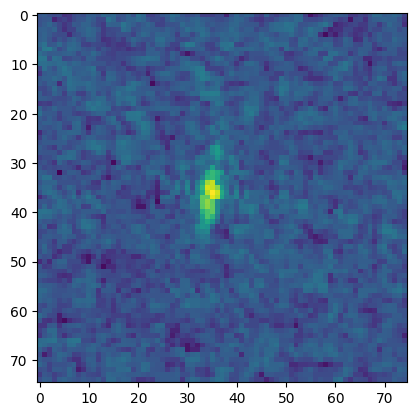

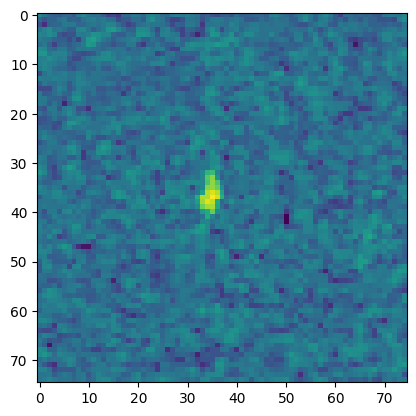

In [7]:
import numpy as np
import matplotlib.pyplot as plt

img1 = np.array(train.loc[0, "band_1"]).reshape(75, 75)
img2 = np.array(train.loc[0, "band_2"]).reshape(75, 75)

plt.imshow(img1)
plt.show()

plt.imshow(img2)
plt.show()

**Iceberg and Ship**


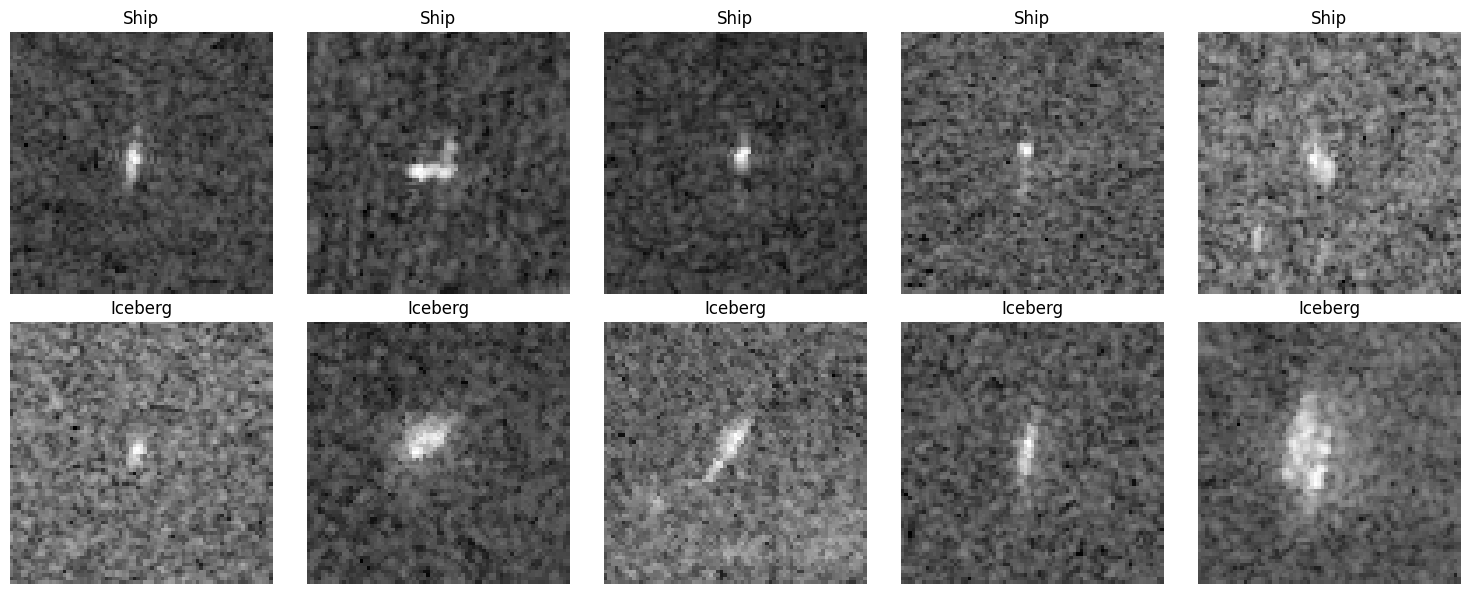

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, label in enumerate([0, 1]):
    samples = train[train["is_iceberg"] == label].head(5)

    for col, (_, sample) in enumerate(samples.iterrows()):
        image = np.array(sample["band_1"]).reshape(75, 75)

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].set_title(
            f"{'Iceberg' if label == 1 else 'Ship'}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


**Pixel Intensity Distribution**


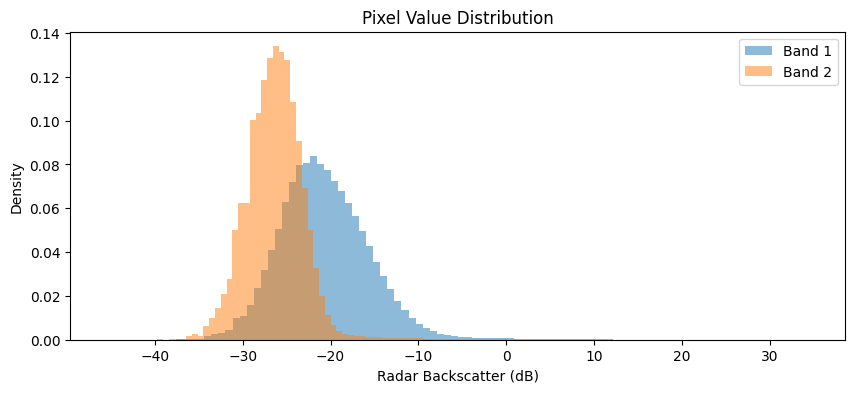

In [10]:
band1 = np.stack(train["band_1"].values)
band2 = np.stack(train["band_2"].values)

plt.figure(figsize=(10, 4))

plt.hist(band1.flatten(), bins=100,
         alpha=0.5, label="Band 1", density=True)
plt.hist(band2.flatten(), bins=100,
         alpha=0.5, label="Band 2", density=True)

plt.xlabel("Radar Backscatter (dB)")
plt.ylabel("Density")
plt.title("Pixel Value Distribution")
plt.legend()
plt.show()

In [11]:
angle = pd.to_numeric(train["inc_angle"], errors="coerce")
print("Missing incidence angles:", angle.isna().sum())

Missing incidence angles: 133
